In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

(x_train,y_train),(x_test,y_test)=tf.keras.datasets.cifar10.load_data()

x_train=x_train[:10000]/255.0
y_train=y_train[:10000]
x_test=x_test[:2000]/255.0
y_test=y_test[:2000]

In [4]:
def create_model(kernel,stride,padding,pool):
    model=tf.keras.Sequential([
        tf.keras.layers.Input(shape=(32,32,3)),
        tf.keras.layers.Conv2D(32,kernel,strides=stride,
                               padding=padding,activation='relu'),
        tf.keras.layers.MaxPooling2D() if pool=='max'
        else tf.keras.layers.AveragePooling2D(pool_size=2),
        tf.keras.layers.Conv2D(64,3,activation='relu'),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128,activation='relu'),
        tf.keras.layers.Dense(10,activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [5]:
results={}

for k in [3,5]:
    for s in [1,2]:
        for p in ['same','valid']:
            for pool in ['max','avg']:

                model=create_model(k,s,p,pool)
                h=model.fit(x_train,y_train,epochs=3,batch_size=64,
                            validation_data=(x_test,y_test),verbose=0)

                acc=model.evaluate(x_test,y_test,verbose=0)[1]
                name=f'{k}x{k},S{s},{p},{pool}'
                results[name]=(h.history['loss'][-1],acc)

                print(name,'Loss:',results[name][0],
                      'Accuracy:',acc*100)

3x3,S1,same,max Loss: 1.1138800382614136 Accuracy: 54.750001430511475
3x3,S1,same,avg Loss: 1.283315658569336 Accuracy: 52.85000205039978
3x3,S1,valid,max Loss: 1.2031364440917969 Accuracy: 53.200000524520874
3x3,S1,valid,avg Loss: 1.3099074363708496 Accuracy: 50.700002908706665
3x3,S2,same,max Loss: 1.409642219543457 Accuracy: 52.64999866485596
3x3,S2,same,avg Loss: 1.4556771516799927 Accuracy: 46.99999988079071
3x3,S2,valid,max Loss: 1.433251142501831 Accuracy: 46.65000140666962
3x3,S2,valid,avg Loss: 1.5169039964675903 Accuracy: 47.69999980926514
5x5,S1,same,max Loss: 1.2554633617401123 Accuracy: 53.60000133514404
5x5,S1,same,avg Loss: 1.3023284673690796 Accuracy: 51.39999985694885
5x5,S1,valid,max Loss: 1.2395645380020142 Accuracy: 54.19999957084656
5x5,S1,valid,avg Loss: 1.33992338180542 Accuracy: 50.349998474121094
5x5,S2,same,max Loss: 1.3671742677688599 Accuracy: 48.60000014305115
5x5,S2,same,avg Loss: 1.433989405632019 Accuracy: 49.70000088214874
5x5,S2,valid,max Loss: 1.39741

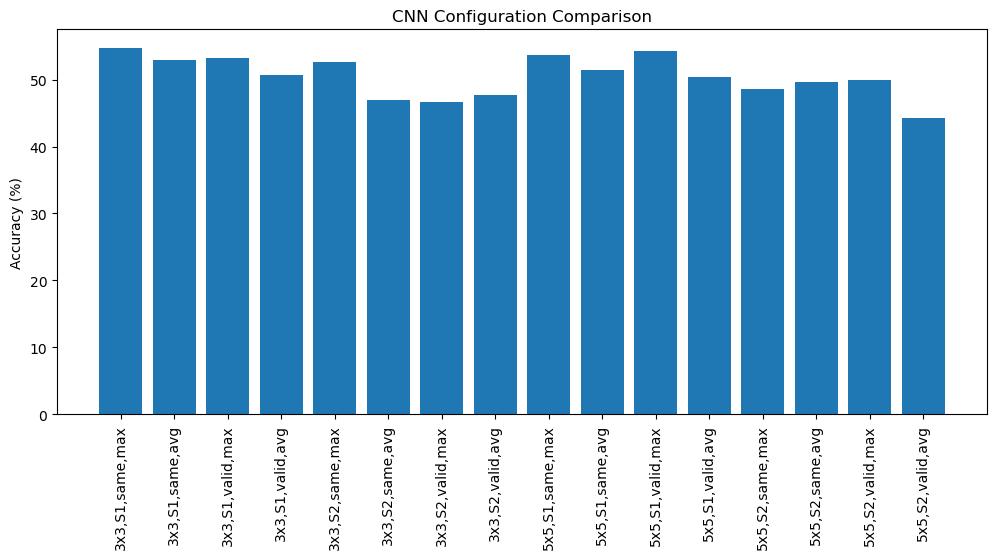

In [6]:
plt.figure(figsize=(12,5))
plt.bar(results.keys(),[v[1]*100 for v in results.values()])
plt.xticks(rotation=90)
plt.ylabel('Accuracy (%)')
plt.title('CNN Configuration Comparison')
plt.show()

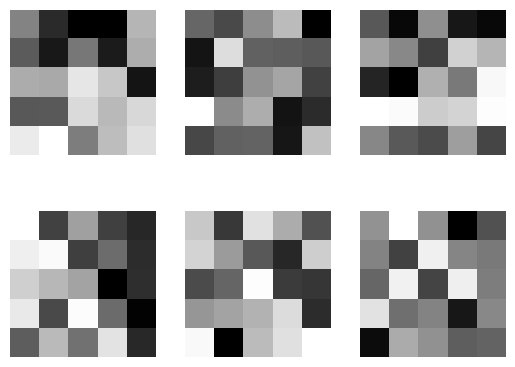

In [7]:
filters=model.layers[0].get_weights()[0]

for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(filters[:,:,0,i],cmap='gray')
    plt.axis('off')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step


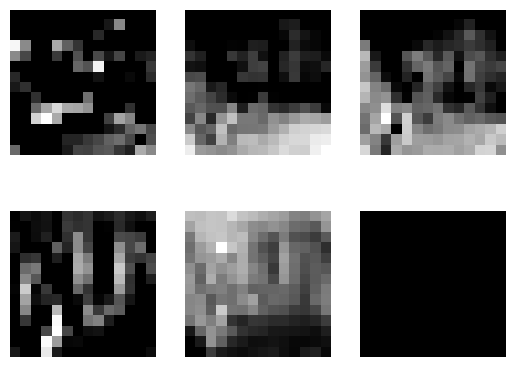

In [11]:
inputs=tf.keras.Input(shape=(32,32,3))
outputs=model.layers[0](inputs)
layer_model=tf.keras.Model(inputs,outputs)

features=layer_model.predict(x_test[:1])

for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(features[0,:,:,i],cmap='gray')
    plt.axis('off')
plt.show()